<a href="https://colab.research.google.com/github/LabWorkAndAnalysis/YAG/blob/main/ThorImageCAM_Beam_Analysis_v7_Reviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ThorImageCAM | Beam characterization and PCA

Analyze independent laser-beam images with **ISO 11146 D4σ radii**, **elliptical Gaussian 1/e² radii**, and their **mean ± sample SD**. The background-corrected, optional intensity-normalized mean image is fitted separately. Beam shapes are measured from image pixels, not generated from a synthetic Gaussian.

**Output:** one compact Excel workbook (**Widths**, **PCA**); one summary figure with Gaussian and spatial-PCA overlays; a between-frame PCA mode montage when ≥3 frames are available; an optional interactive 3D comparison; the original uploaded images; and a readable calibration/settings record. All are packaged in a ZIP whose name you choose.

All 2D camera maps use **X rightwards, Y downwards**. Widths are **radii**, in µm, calibrated to the sensor plane unless a verified imaging magnification is supplied.

In [ ]:
%pip -q install numpy scipy pillow matplotlib plotly openpyxl

In [ ]:
import re, tempfile, zipfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import gaussian_filter, label, shift as ndi_shift, zoom as ndi_zoom
from scipy.optimize import least_squares
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display
from openpyxl import Workbook
from openpyxl.styles import Alignment, Font, PatternFill

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 12, 'axes.labelsize': 10.5,
    'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
    'figure.dpi': 115, 'savefig.dpi': 240,
    'axes.spines.top': False, 'axes.spines.right': False,
})

## 1 · Settings

Set your ZIP filename and the camera calibration. Use `REFERENCE_ONLY_IMAGE_NAMES` for camera-settings screenshots that should be archived but not measured. Native 1440 × 1080 frames use the 3.45 µm sensor pitch; cropped desktop previews require a verified, full-frame entry in `SCREENSHOT_CROPS`.

In [ ]:
ZIP_FILENAME = 'Laser_Beam_Analysis.zip'
SENSOR_SIZE_PX = (1440, 1080)            # Width, height
UM_PER_SENSOR_PIXEL = (3.45, 3.45)        # Sensor X and Y at 1×1 binning
OBJECT_MAGNIFICATION = None               # Supply only if independently calibrated

REFERENCE_ONLY_IMAGE_NAMES = []           # Example: ['Camera_Settings.png']
SCREENSHOT_CROPS = {}                     # {'photo.png': (left, top, right, bottom)}
ALIGN_FOR_MEAN = True
NORMALIZE_INTENSITY_FOR_MEAN = True
MAKE_INTERACTIVE_3D = True
DOWNLOAD_ZIP_IN_COLAB = True

BACKGROUND_ORDER = 2
ROI_EXPANSION_SIGMA = 6.0
ROI_MIN_HALF_SIZE_PX = 65
GAUSSIAN_FIT_GRID_MAX = 145
INPUT_FOLDER = Path('beam_inputs')
INPUT_FOLDER.mkdir(exist_ok=True)

if BACKGROUND_ORDER not in (0, 1, 2):
    raise ValueError('BACKGROUND_ORDER must be 0, 1 or 2')
if OBJECT_MAGNIFICATION is not None and OBJECT_MAGNIFICATION <= 0:
    raise ValueError('OBJECT_MAGNIFICATION must be positive')
ZIP_FILENAME = re.sub(r'[^A-Za-z0-9_.-]+', '_', ZIP_FILENAME.strip())
if not ZIP_FILENAME.lower().endswith('.zip'):
    ZIP_FILENAME += '.zip'
if ZIP_FILENAME.startswith('.'):
    ZIP_FILENAME = 'Laser_Beam_Analysis.zip'
print('Report:', ZIP_FILENAME)

Report: Laser_Beam_Analysis.zip


## 2 · Upload images

Upload independent beam frames. You may upload a separate settings screenshot for archiving. Avoid including the same exposure twice (for example, as both a native frame and a desktop screenshot).

In [ ]:
EXTENSIONS = {'.jpg','.jpeg','.png','.tif','.tiff','.bmp'}
if IN_COLAB:
    uploaded = colab_files.upload()
    input_paths = []
    for filename, content in uploaded.items():
        path = INPUT_FOLDER / Path(filename).name
        if path.suffix.lower() not in EXTENSIONS: continue
        path.write_bytes(content)
        input_paths.append(path)
else:
    input_paths = sorted(p for p in INPUT_FOLDER.iterdir()
                         if p.suffix.lower() in EXTENSIONS and p.is_file())
if not input_paths:
    raise FileNotFoundError('No beam images found. Upload files or put them in beam_inputs/.')
reference_only = {str(s).casefold() for s in REFERENCE_ONLY_IMAGE_NAMES}
reference_paths = [p for p in input_paths if p.name.casefold() in reference_only]
measurement_paths = [p for p in input_paths if p.name.casefold() not in reference_only]
if not measurement_paths:
    raise FileNotFoundError('No measurement images selected; check REFERENCE_ONLY_IMAGE_NAMES.')
print('Measurement images:', [p.name for p in measurement_paths])
if reference_paths: print('Reference-only screenshots:', [p.name for p in reference_paths])

Saving Snapshot_YAG-Target_0103.jpg to Snapshot_YAG-Target_0103.jpg
Saving Snapshot_YAG-Target_0102.jpg to Snapshot_YAG-Target_0102.jpg
Saving Snapshot_YAG-Target_0101.jpg to Snapshot_YAG-Target_0101.jpg
Saving Snapshot_YAG-Target_0100.jpg to Snapshot_YAG-Target_0100.jpg
Saving Snapshot_YAG-Target_0099.jpg to Snapshot_YAG-Target_0099.jpg
Saving Snapshot_YAG-Target_0098.jpg to Snapshot_YAG-Target_0098.jpg
Saving Snapshot_YAG-Target_0097.jpg to Snapshot_YAG-Target_0097.jpg
Saving Snapshot_YAG-Target_0096.jpg to Snapshot_YAG-Target_0096.jpg
Saving Snapshot_YAG-Target_0095.jpg to Snapshot_YAG-Target_0095.jpg
Saving Snapshot_YAG-Target_0094.jpg to Snapshot_YAG-Target_0094.jpg
Saving Snapshot_YAG-Target_0093.jpg to Snapshot_YAG-Target_0093.jpg
Saving Snapshot_YAG-Target_0092.jpg to Snapshot_YAG-Target_0092.jpg
Saving Snapshot_YAG-Target_0091.jpg to Snapshot_YAG-Target_0091.jpg
Saving Snapshot_YAG-Target_0090.jpg to Snapshot_YAG-Target_0090.jpg
Saving Snapshot_YAG-Target_0089.jpg to Snapshot_

## 3 · Measurement model

Each frame is independently background-corrected and measured using intensity-weighted second moments, a fitted 2D Gaussian and spatial PCA. Quality flags indicate possible low signal, clipped regions or poor fits. No individual-frame figures are exported.

In [ ]:
def read_image_array(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        if im.mode in ('L','I','I;16','F'):
            return np.asarray(im, dtype=np.float64)
        rgb = np.asarray(im.convert('RGB'), dtype=np.float64)
        return np.dot(rgb[..., :3], [0.2126, 0.7152, 0.0722])


def prepare_image(path):
    raw = read_image_array(path)
    sw, sh = SENSOR_SIZE_PX
    kind = 'native image'
    if raw.shape != (sh, sw):
        crop = SCREENSHOT_CROPS.get(path.name)
        if crop is None:
            raise ValueError(f'Image shape {raw.shape} is not the full sensor (h,w)={(sh,sw)}. '
                             'Add a verified full-preview rectangle to SCREENSHOT_CROPS.')
        left,top,right,bottom = crop
        if not (0 <= left < right <= raw.shape[1] and 0 <= top < bottom <= raw.shape[0]):
            raise ValueError('Invalid screenshot crop')
        raw = raw[top:bottom,left:right]
        if abs((raw.shape[1]/raw.shape[0])/(sw/sh)-1) > 0.025:
            raise ValueError('Screenshot preview is not the expected 4:3 sensor shape')
        raw = np.array(Image.fromarray(raw.astype(np.float32)).resize(
            (sw,sh), resample=Image.Resampling.BILINEAR), dtype=np.float64)
        kind = 'rescaled full-frame screenshot (approximate)'
    sx, sy = UM_PER_SENSOR_PIXEL
    if OBJECT_MAGNIFICATION is not None: sx, sy = sx/OBJECT_MAGNIFICATION,sy/OBJECT_MAGNIFICATION
    return dict(name=path.name, raw=raw, sx=float(sx), sy=float(sy), kind=kind,
                plane='sensor' if OBJECT_MAGNIFICATION is None else 'object')


def fit_background_poly(raw, order=2):
    h, w = raw.shape
    ys, xs = np.mgrid[0:h:4, 0:w:4]
    samples = raw[::4, ::4].ravel()
    x = (xs.ravel() - (w - 1) / 2) / max(w, 1)
    y = (ys.ravel() - (h - 1) / 2) / max(h, 1)
    edge = (np.abs(x) > .36) | (np.abs(y) > .36)

    def features(x, y):
        parts = [np.ones_like(x)]
        if order >= 1: parts += [x, y]
        if order >= 2: parts += [x*x, x*y, y*y]
        return np.column_stack(parts)

    M = features(x[edge], y[edge]); b = samples[edge]
    good = np.isfinite(b)
    for _ in range(5):
        beta, *_ = np.linalg.lstsq(M[good], b[good], rcond=None)
        residual = b - M @ beta
        med = np.median(residual[good])
        mad = 1.4826 * np.median(np.abs(residual[good] - med))
        sigma = max(mad, 0.3)
        good = np.abs(residual - med) <= max(3.5*sigma, 0.9)
    noise_sigma = max(1.4826 * np.median(np.abs(residual[good] - np.median(residual[good]))), 0.3)

    yy, xx = np.indices(raw.shape, dtype=np.float32)
    xn = (xx - (w - 1) / 2) / w
    yn = (yy - (h - 1) / 2) / h
    bg = np.full(raw.shape, beta[0], dtype=np.float32)
    if order >= 1: bg += beta[1]*xn + beta[2]*yn
    if order >= 2: bg += beta[3]*xn*xn + beta[4]*xn*yn + beta[5]*yn*yn
    return bg.astype(np.float64), float(noise_sigma)


def locate_beam(signal, noise_std):
    h, w = signal.shape
    smoothed = gaussian_filter(signal, 2.0)
    py, px = np.unravel_index(np.nanargmax(smoothed), smoothed.shape)
    amp = float(smoothed[py, px])
    if amp < max(5*noise_std, 2):
        raise ValueError(f"Beam undetectable: smoothed peak {amp:.2f} vs noise {noise_std:.2f}")
    thresh = max(3*noise_std, 0.075*amp)
    tags, n = label(smoothed > thresh)
    sel = tags[py,px]
    if sel == 0: raise ValueError("Could not segment beam")
    m = tags == sel
    yy, xx = np.nonzero(m)
    wt = np.maximum(smoothed[m], 0)
    if len(wt) < 30 or wt.sum() <= 0: raise ValueError("Too few detected beam pixels")
    cx, cy = np.average(xx, weights=wt), np.average(yy, weights=wt)
    sigx = np.sqrt(np.average((xx-cx)**2, weights=wt))
    sigy = np.sqrt(np.average((yy-cy)**2, weights=wt))
    half_x = max(ROI_MIN_HALF_SIZE_PX, ROI_EXPANSION_SIGMA * sigx)
    half_y = max(ROI_MIN_HALF_SIZE_PX, ROI_EXPANSION_SIGMA * sigy)
    x0 = max(0, int(np.floor(cx-half_x))); x1 = min(w, int(np.ceil(cx+half_x+1)))
    y0 = max(0, int(np.floor(cy-half_y))); y1 = min(h, int(np.ceil(cy+half_y+1)))
    if (x1-x0) < 40 or (y1-y0) < 40: raise ValueError("Beam ROI too small")
    return (x0,y0,x1,y1), (float(cx),float(cy)), (float(sigx),float(sigy)), amp


def spatial_pca(covariance):
    """Intensity-weighted *spatial* PCA: eigendecomposition of the D4σ covariance.

    Principal radii = 2 sqrt(eigenvalues). This is mathematically identical to
    the principal-axis ISO second moments, NOT a separate beam-width estimator.
    Image y increases downward; angle is measured clockwise on the display.
    """
    eigvals, eigvecs = np.linalg.eigh(np.asarray(covariance, dtype=float))
    if eigvals[0] <= 0 or not np.all(np.isfinite(eigvals)):
        raise ValueError('PCA covariance non-positive: review ROI/background')
    major_vec, minor_vec = eigvecs[:,1], eigvecs[:,0]
    angle = (np.degrees(np.arctan2(major_vec[1], major_vec[0])) + 90) % 180 - 90
    return {
        'pca_major_width_um':float(2*np.sqrt(eigvals[1])),
        'pca_minor_width_um':float(2*np.sqrt(eigvals[0])),
        'pca_major_D4sigma_um':float(4*np.sqrt(eigvals[1])),
        'pca_minor_D4sigma_um':float(4*np.sqrt(eigvals[0])),
        'pca_angle_deg_image_y_down':float(angle),
        'pca_variance_major_fraction':float(eigvals[1]/eigvals.sum()),
        'pca_variance_minor_fraction':float(eigvals[0]/eigvals.sum()),
        'pca_minor_over_major_width':float(np.sqrt(eigvals[0]/eigvals[1])),
        'pca_cov_xx_um2':float(covariance[0,0]),
        'pca_cov_xy_um2':float(covariance[0,1]),
        'pca_cov_yy_um2':float(covariance[1,1]),
    }


def iso_moments(intensity, roi, sx, sy):
    """D4sigma = 4*sqrt(second central moment), without positive-noise clipping."""
    x0,y0,x1,y1 = roi
    data = intensity[y0:y1, x0:x1]
    iy, ix = np.indices(data.shape)
    x = (ix+x0) * sx; y = (iy+y0) * sy
    p = float(data.sum())
    if not np.isfinite(p) or p <= 0: raise ValueError("Nonpositive integrated signal; review background and ROI")
    mx, my = (data*x).sum()/p, (data*y).sum()/p
    vx = (data*(x-mx)**2).sum()/p
    vy = (data*(y-my)**2).sum()/p
    vxy = (data*(x-mx)*(y-my)).sum()/p
    cov = np.array([[vx, vxy],[vxy,vy]],dtype=float)
    if np.linalg.eigvalsh(cov).min() <= 0:
        raise ValueError("Non-positive second-moment covariance; review background, ROI, and SNR")
    vals, vectors = np.linalg.eigh(cov)
    major_axis = vectors[:, 1]
    theta = (np.degrees(np.arctan2(major_axis[1],major_axis[0])) + 90) % 180 - 90
    return {
        "centroid_x_um": float(mx), "centroid_y_um": float(my),
        "centroid_x_px": float(mx/sx), "centroid_y_px": float(my/sy),
        "iso_wx_um": float(2*np.sqrt(vx)), "iso_wy_um": float(2*np.sqrt(vy)),
        "iso_D4sig_x_um": float(4*np.sqrt(vx)), "iso_D4sig_y_um": float(4*np.sqrt(vy)),
        "iso_D4sig_major_um": float(4*np.sqrt(vals[1])),
        "iso_D4sig_minor_um": float(4*np.sqrt(vals[0])),
        "iso_angle_deg_image_y_down": float(theta),
        "integrated_counts_background_corrected": p,
        "moment_covariance_um2": cov,
    }


def gaussian2d(x, y, A, cx, cy, wx, wy, theta, C=0.0):
    ct, st = np.cos(theta), np.sin(theta)
    dx,dy=x-cx,y-cy
    xp =  ct*dx + st*dy
    yp = -st*dx + ct*dy
    return C + A*np.exp(-2.0*((xp/wx)**2 + (yp/wy)**2))


def fit_gaussian(signal, roi, sx, sy, initial_moments, noise_std):
    x0,y0,x1,y1=roi
    stride=max(1, int(np.ceil(max(x1-x0,y1-y0)/GAUSSIAN_FIT_GRID_MAX)))
    yi,xi=np.mgrid[y0:y1:stride,x0:x1:stride]
    x=xi*sx; y=yi*sy; z=signal[y0:y1:stride,x0:x1:stride]
    noise=max(noise_std, 0.4)
    amp0=max(np.percentile(z,99.9)-np.median(z), noise*3)
    cx0,cy0=initial_moments['centroid_x_um'],initial_moments['centroid_y_um']
    wx0=max(initial_moments['iso_wx_um'], 3*sx)
    wy0=max(initial_moments['iso_wy_um'], 3*sy)
    theta0=np.deg2rad(initial_moments['iso_angle_deg_image_y_down'])
    max_w=max((x1-x0)*sx,(y1-y0)*sy)*2
    lo=[0, x0*sx, y0*sy, sx*2, sy*2, -np.pi/2, -max(amp0,20)]
    hi=[max(amp0*5,30), x1*sx, y1*sy, max_w, max_w, np.pi/2, max(amp0,20)]
    p0=np.array([amp0,cx0,cy0,wx0,wy0,theta0,0.])
    p0=np.maximum(np.minimum(p0,np.array(hi)-1e-5),np.array(lo)+1e-5)
    fun=lambda p: (gaussian2d(x,y,*p)-z).ravel()
    res=least_squares(fun,p0,bounds=(lo,hi),loss="soft_l1",
                      f_scale=noise*2, max_nfev=100)
    A,cx,cy,wa,wb,theta,C=map(float,res.x)
    if wb>wa:
        wa,wb=wb,wa; theta+=np.pi/2
    theta=(theta + np.pi/2) % np.pi - np.pi/2
    # Projection widths of rotated elliptical Gaussian onto x/y axes.
    sigx_sq=(wa/2)**2*np.cos(theta)**2 + (wb/2)**2*np.sin(theta)**2
    sigy_sq=(wa/2)**2*np.sin(theta)**2 + (wb/2)**2*np.cos(theta)**2
    pred=gaussian2d(x,y,*res.x)
    core=(pred-C) > max(0.05*A, 1.5*noise)
    if core.sum()<50: core=np.ones_like(core,dtype=bool)
    yy0=z[core]; yyhat=pred[core]
    SSE=np.sum((yy0-yyhat)**2)
    SST=np.sum((yy0-yy0.mean())**2)
    r2=float(1-SSE/SST) if SST>0 else np.nan
    rmse=float(np.sqrt(np.mean((yy0-yyhat)**2)))
    full_r2=float(1-np.sum((z-pred)**2)/max(np.sum((z-z.mean())**2),1e-12))
    return {
        "fit_A_counts":A,"fit_cx_um":cx,"fit_cy_um":cy,
        "fit_major_radius_um":wa,"fit_minor_radius_um":wb,
        "fit_angle_deg_image_y_down":float(np.degrees(theta)),
        "fit_wx_um":float(2*np.sqrt(sigx_sq)), "fit_wy_um":float(2*np.sqrt(sigy_sq)),
        "fit_Dx_um":float(4*np.sqrt(sigx_sq)), "fit_Dy_um":float(4*np.sqrt(sigy_sq)),
        "fit_ellipticity_minor_over_major":float(wb/wa),
        "fit_offset_counts":C,"fit_R2_core":r2,"fit_R2_full_roi":full_r2,
        "fit_RMSE_core_counts":rmse,"fit_NRMSE_core_over_peak":rmse/max(A,1e-9),
        "fit_converged":bool(res.success),
        "gaussian_params":(A,cx,cy,wa,wb,theta,C),
    }

## 4 · Individual frame measurements

The table retains X/Y beam radii and Gaussian-fit quality for every accepted frame.

In [ ]:
def analyze_frame(meta):
    raw, sx, sy = meta['raw'], meta['sx'], meta['sy']
    background, noise = fit_background_poly(raw, BACKGROUND_ORDER)
    signal = raw - background
    roi, _, _, peak = locate_beam(signal, noise)
    iso = iso_moments(signal, roi, sx, sy)
    gaussian = fit_gaussian(signal, roi, sx, sy, iso, noise)
    pca = spatial_pca(iso['moment_covariance_um2'])
    x0,y0,x1,y1 = roi
    flags = []
    if 'screenshot' in meta['kind']: flags.append('Resampled screenshot: scale approximate')
    if peak < 15*noise: flags.append('Low signal-to-noise')
    if (x0 == 0 or y0 == 0 or x1 == raw.shape[1] or y1 == raw.shape[0]):
        flags.append('ROI touches image boundary')
    if gaussian['fit_R2_core'] < .90: flags.append('Gaussian core fit R2 < 0.9')
    if not gaussian['fit_converged']: flags.append('Gaussian optimizer did not converge')
    # Only detect obvious display clipping, not sensor saturation in unknown raw formats.
    if raw.max() <= 255 and np.sum(raw >= 254.99) > 0:
        flags.append('Possible 8-bit clipping/saturation')
    row = {'Image': meta['name'],
        'ISO width X (um)': iso['iso_wx_um'], 'ISO width Y (um)':iso['iso_wy_um'],
        'Gaussian width X (um)':gaussian['fit_wx_um'], 'Gaussian width Y (um)':gaussian['fit_wy_um'],
        'ISO D4sigma X (um)':iso['iso_D4sig_x_um'], 'ISO D4sigma Y (um)':iso['iso_D4sig_y_um'],
        'Gaussian diameter X (um)':gaussian['fit_Dx_um'],
        'Gaussian diameter Y (um)':gaussian['fit_Dy_um'],
        'Centroid X (um)':iso['centroid_x_um'],'Centroid Y (um)':iso['centroid_y_um'],
        'PCA major width (um)':pca['pca_major_width_um'],
        'PCA minor width (um)':pca['pca_minor_width_um'],
        'PCA angle (deg)':pca['pca_angle_deg_image_y_down'],
        'PCA major variance (%)':100*pca['pca_variance_major_fraction'],
        'PCA ellipticity':pca['pca_minor_over_major_width'],
        'Gaussian ellipticity':gaussian['fit_ellipticity_minor_over_major'],
        'Gaussian core R2':gaussian['fit_R2_core'],
        'Quality notes':' | '.join(flags)}
    return dict(meta=meta,signal=signal,roi=roi,iso=iso,fit=gaussian,pca=pca,
                row=row,noise=noise,flags=flags)

results, skipped = [], []
for path in measurement_paths:
    try:
        r = analyze_frame(prepare_image(path))
        results.append(r)
        print(f"✓ {path.name}: ISO wx={r['iso']['iso_wx_um']:.2f}, "
              f"wy={r['iso']['iso_wy_um']:.2f} um; R2={r['fit']['fit_R2_core']:.3f}")
        if r['flags']: print('   Note:', ' | '.join(r['flags']))
    except Exception as exc:
        msg=f'{type(exc).__name__}: {exc}'
        skipped.append({'Image':path.name,'Reason':msg})
        print(f'✗ Skipped {path.name}: {msg}')
if not results: raise RuntimeError('No valid frames. Check uploaded files and calibration settings.')

✓ Snapshot_YAG-Target_0103.jpg: ISO wx=316.14, wy=511.27 um; R2=0.932
✓ Snapshot_YAG-Target_0102.jpg: ISO wx=360.07, wy=532.56 um; R2=0.947
✓ Snapshot_YAG-Target_0101.jpg: ISO wx=385.73, wy=575.81 um; R2=0.965
✓ Snapshot_YAG-Target_0100.jpg: ISO wx=351.87, wy=527.71 um; R2=0.947
✓ Snapshot_YAG-Target_0099.jpg: ISO wx=381.79, wy=558.08 um; R2=0.953
✓ Snapshot_YAG-Target_0098.jpg: ISO wx=353.89, wy=528.69 um; R2=0.932
✓ Snapshot_YAG-Target_0097.jpg: ISO wx=368.30, wy=553.19 um; R2=0.934
✓ Snapshot_YAG-Target_0096.jpg: ISO wx=388.33, wy=570.08 um; R2=0.836
   Note: Gaussian core fit R2 < 0.9
✓ Snapshot_YAG-Target_0095.jpg: ISO wx=361.57, wy=534.55 um; R2=0.949
✓ Snapshot_YAG-Target_0094.jpg: ISO wx=325.91, wy=459.82 um; R2=0.880
   Note: Gaussian core fit R2 < 0.9
✓ Snapshot_YAG-Target_0093.jpg: ISO wx=381.35, wy=561.34 um; R2=0.961
✓ Snapshot_YAG-Target_0092.jpg: ISO wx=325.15, wy=472.60 um; R2=0.939
✓ Snapshot_YAG-Target_0091.jpg: ISO wx=328.01, wy=482.74 um; R2=0.926
✓ Snapshot_YAG-Tar

## 5 · Average image and uncertainty

Accepted frames are analyzed individually. For averaging, their background-corrected intensities are optionally normalized and centroid-aligned. The report separates the **mean ± sample SD of individual widths** from the **width measured directly on the mean image**. With one frame, sample SD is undefined.

In [ ]:
# All frames must share an identical sensor grid and scale.
ref = results[0]['meta']
valid, excluded = [], []
for r in results:
    m = r['meta']
    if m['raw'].shape == ref['raw'].shape and np.isclose(m['sx'],ref['sx']) and np.isclose(m['sy'],ref['sy']):
        valid.append(r)
    else:
        excluded.append(m['name'])
if excluded: print('Excluded from average (different calibrated grid):', excluded)
if not valid: raise RuntimeError('No mutually compatible frames.')

n = len(valid)
centers = np.array([[r['iso']['centroid_x_px'],r['iso']['centroid_y_px']] for r in valid])
center = centers.mean(axis=0)
stack = []
for r, (cx,cy) in zip(valid, centers):
    signal = r['signal']
    if NORMALIZE_INTENSITY_FOR_MEAN:
        # All frames are expressed on the same nominal Gaussian-peak intensity scale.
        amp = r['fit']['fit_A_counts']
        if not np.isfinite(amp) or amp <= 0: raise ValueError('Invalid fitted amplitude')
        signal = signal * (100.0 / amp)
    if ALIGN_FOR_MEAN:
        signal = ndi_shift(signal, shift=(center[1]-cy,center[0]-cx),
                           order=1, mode='constant', cval=0.0, prefilter=False)
    stack.append(signal)
stack = np.stack(stack, axis=0)
mean_signal = np.mean(stack, axis=0)
sd_signal = np.std(stack, axis=0, ddof=1) if n>1 else np.zeros_like(mean_signal)

# Fit the averaged image using the same measurement pipeline.
mean_meta = {**ref, 'name':f'AVERAGE ({n} independent frames)',
             'raw':mean_signal, 'kind':'mean background-corrected normalized image'}
mean_result = analyze_frame(mean_meta)

metrics = ['ISO width X (um)','ISO width Y (um)',
           'Gaussian width X (um)','Gaussian width Y (um)']
width_stats = []
for metric in metrics:
    values = np.asarray([r['row'][metric] for r in valid],dtype=float)
    avg = float(np.mean(values))
    sd = float(np.std(values,ddof=1)) if n>1 else None
    mean_fit = float(mean_result['row'][metric])
    width_stats.append({'Parameter':metric,'N':n,'Mean of individual images (um)':avg,
        'SD of individual images (um)':sd,'Mean ± SD (um)':
        f'{avg:.3f} ± {sd:.3f}' if sd is not None else f'{avg:.3f} (SD unavailable, N=1)',
        'Width from averaged image (um)':mean_fit,
        'Averaged-image minus individual mean (um)':mean_fit-avg})

print(f'Independent frames in average: {n} (alignment={ALIGN_FOR_MEAN}, normalized={NORMALIZE_INTENSITY_FOR_MEAN})')
print('WIDTHS: mean ± sample SD across independent images')
for row in width_stats[:4]:
    print(f" {row['Parameter']}: {row['Mean ± SD (um)']}; "
          f"mean-image width={row['Width from averaged image (um)']:.2f} um")
if n == 1: print('Only one image: per-image SD and pixelwise SD are not statistically defined.')

Independent frames in average: 29 (alignment=True, normalized=True)
WIDTHS: mean ± sample SD across independent images
 ISO width X (um): 353.999 ± 23.738; mean-image width=386.82 um
 ISO width Y (um): 519.748 ± 31.170; mean-image width=564.77 um
 Gaussian width X (um): 427.985 ± 13.463; mean-image width=426.97 um
 Gaussian width Y (um): 604.339 ± 10.625; mean-image width=606.22 um


## 6 · Principal-component analysis

**Spatial PCA** finds the major and minor axes of the beam's intensity-weighted covariance (the same second moments used for ISO D4σ). **Between-frame PCA**, when ≥3 images are available, identifies spatial patterns of frame-to-frame intensity variation. PCA eigenimage colours represent signed modes, not absolute beam intensity.

In [ ]:
pca_table = []
for r in valid + [mean_result]:
    p = r['pca']
    pca_table.append({
        'Image':r['meta']['name'],
        'PCA major width (um)':p['pca_major_width_um'],
        'PCA minor width (um)':p['pca_minor_width_um'],
        'PCA angle (deg)':p['pca_angle_deg_image_y_down'],
        'Major variance (%)':100*p['pca_variance_major_fraction'],
        'Minor/major width':p['pca_minor_over_major_width']})

# Between-frame PCA uses the actual normalized/registered intensity array.
# The Gram eigendecomposition scales well: n_frames x n_frames rather than n_pixels x n_pixels.
frame_pca_table, frame_scores_table, ensemble_pca = [], [], None
if n >= 3:
    x0,y0,x1,y1 = mean_result['roi']
    # Resample the same measured/normalized/aligned intensity ROI from every frame.
    # Resampling is solely to keep the PCA matrix small; not a Gaussian simulation.
    roi_stack = stack[:, y0:y1, x0:x1]
    pca_size = 80                 # output eigenimage shape, in resampled pixels
    resized = []
    for frame in roi_stack:
        a = ndi_zoom(frame, (pca_size/frame.shape[0],pca_size/frame.shape[1]),
                     order=1, prefilter=False)
        resized.append(a[:pca_size,:pca_size])
    a = np.stack(resized).astype(np.float64)
    shape = a.shape[1:]
    data_matrix = a.reshape(n,-1)
    mean_vector = data_matrix.mean(axis=0)
    centered = data_matrix - mean_vector[None,:]
    # Small Gram eigendecomposition (N x N), avoids a 6400 x 6400 covariance.
    gram = centered @ centered.T
    vals, vecs = np.linalg.eigh(gram)
    order = np.argsort(vals)[::-1]
    vals = np.maximum(vals[order], 0.)
    vecs = vecs[:,order]
    total = float(vals.sum())
    if total > 1e-12:
        # rank <= n-1, so a genuine PC3 requires >=4 independent images.
        proportions = vals/total
        rank = min(3, n-1, int(np.sum(vals > total*1e-11)))
        score_matrix = vecs[:,:rank] * np.sqrt(vals[:rank])[None,:]
        modes = []
        for j in range(rank):
            mode = (centered.T @ vecs[:,j]) / np.sqrt(vals[j])
            # Eigenimage sign is arbitrary; choose a reproducible convention.
            pivot = np.argmax(np.abs(mode))
            if mode[pivot] < 0:
                mode = -mode
                score_matrix[:,j] *= -1
            modes.append(mode.reshape(shape))
            frame_pca_table.append({
                'Component':f'PC{j+1}',
                'Explained variance (%)':float(proportions[j]*100),
                'Number of frames':n})
        for i,r in enumerate(valid):
            frame_scores_table.append({
                'Image':r['meta']['name'],
                'PC1 score':float(score_matrix[i,0]),
                'PC2 score':float(score_matrix[i,1]) if rank>=2 else None})
        ensemble_pca = {'mean_roi':mean_vector.reshape(shape),
                        'modes':modes, 'ratios':proportions, 'scores':score_matrix,
                        'shape':shape, 'roi':(x0,y0,x1,y1)}
        print('Between-frame PCA mode variance (%):',
              [round(float(proportions[j]*100),2) for j in range(rank)])
        if n == 3:
            print('Exactly 3 frames: 2 nonzero PCA modes are possible. Add a fourth frame for PC3.')
    else:
        print('Between-frame PCA: no measurable intensity-pattern variation.')
else:
    print('At least 3 independent images are needed for between-frame PCA eigenimage maps; spatial PCA is still available.')


Between-frame PCA mode variance (%): [15.04, 10.05, 8.74]


## 7 · Figures

The **beam summary** combines the measured mean image, Gaussian 1/e² contour, spatial-PCA ellipse/axes, fit residual, image-to-image SD, X/Y profiles, and width statistics. The **PCA mode-map figure** is produced separately only when enough independent frames are available. The optional interactive 3D view compares measured and fitted average intensities.

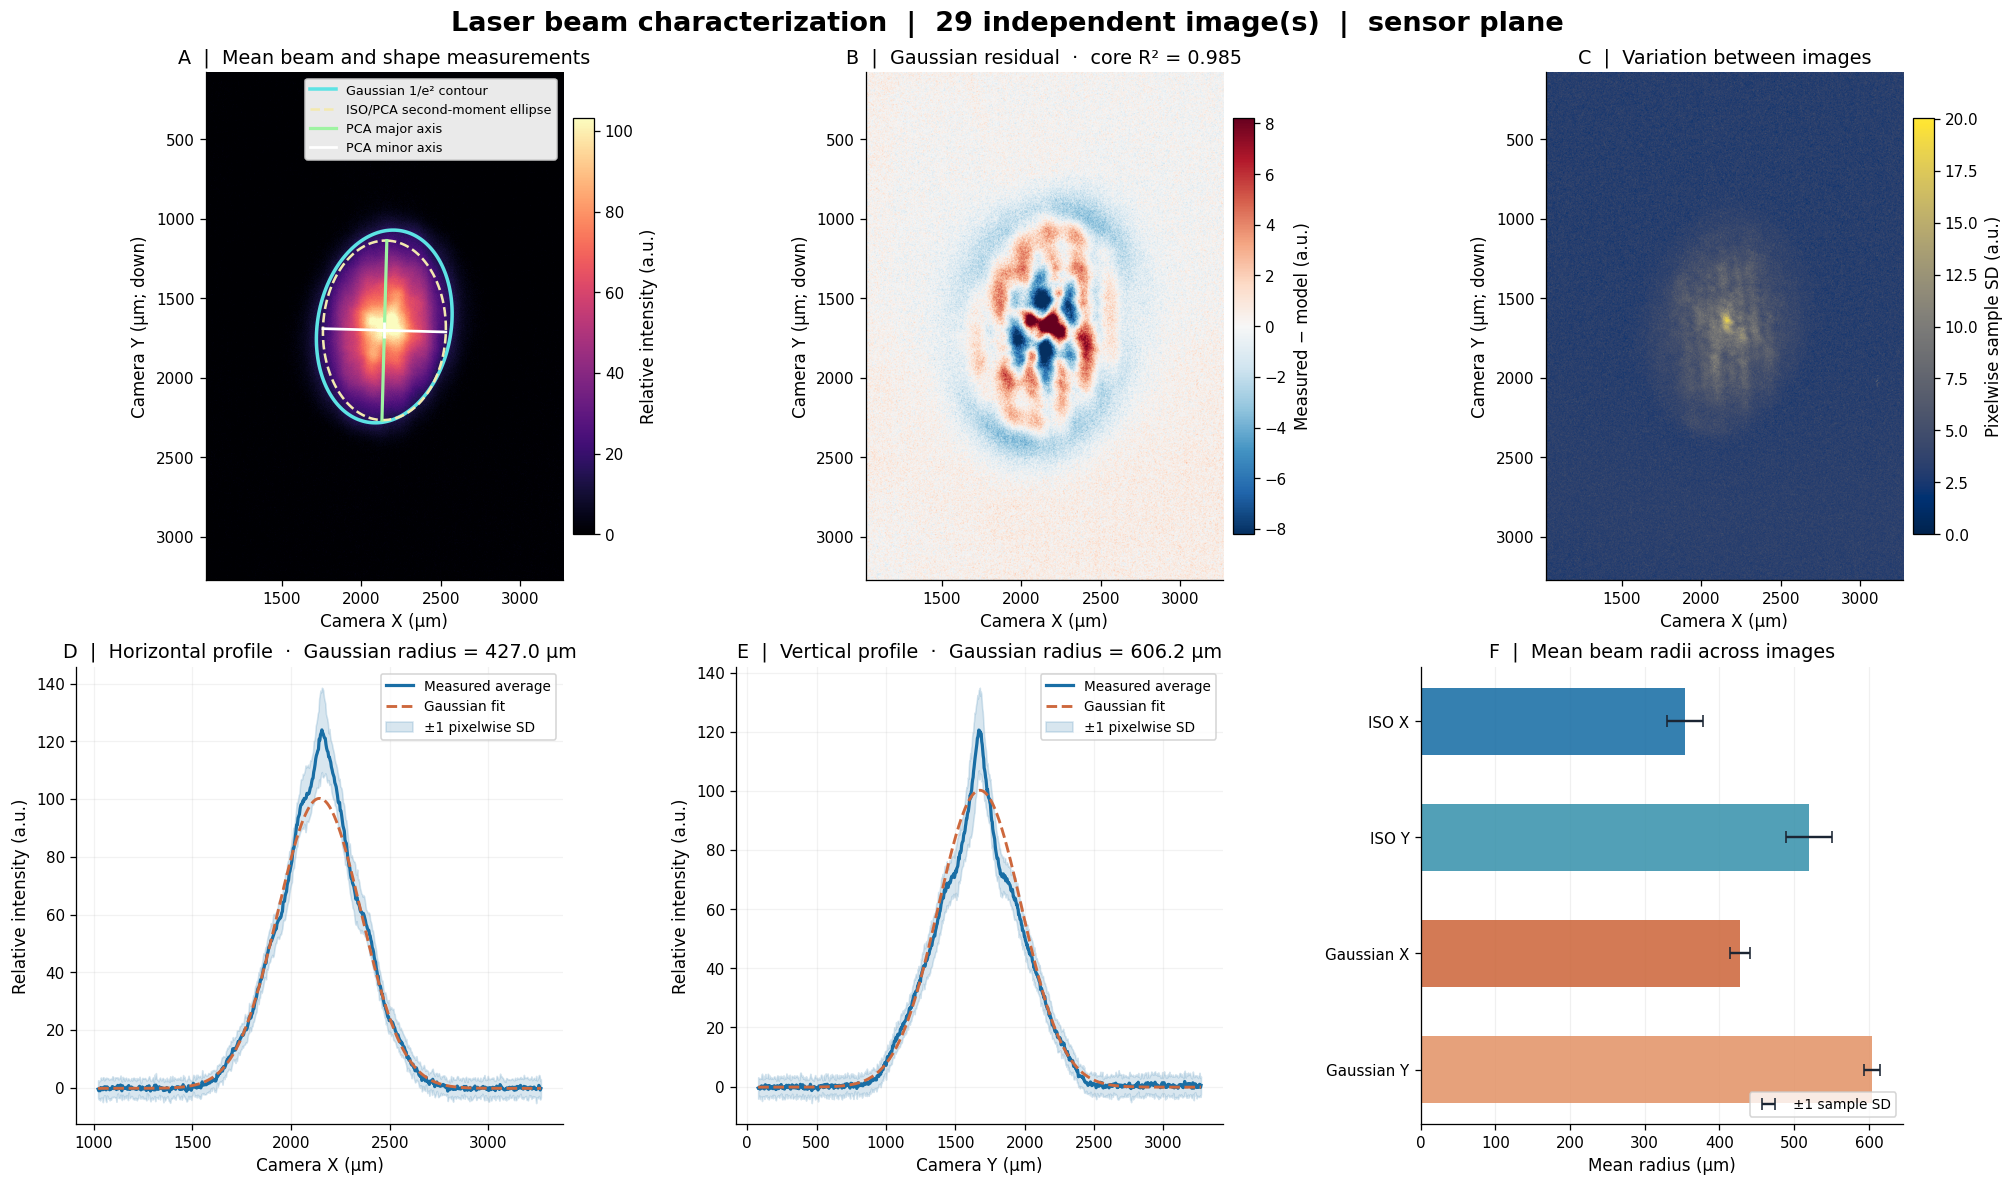

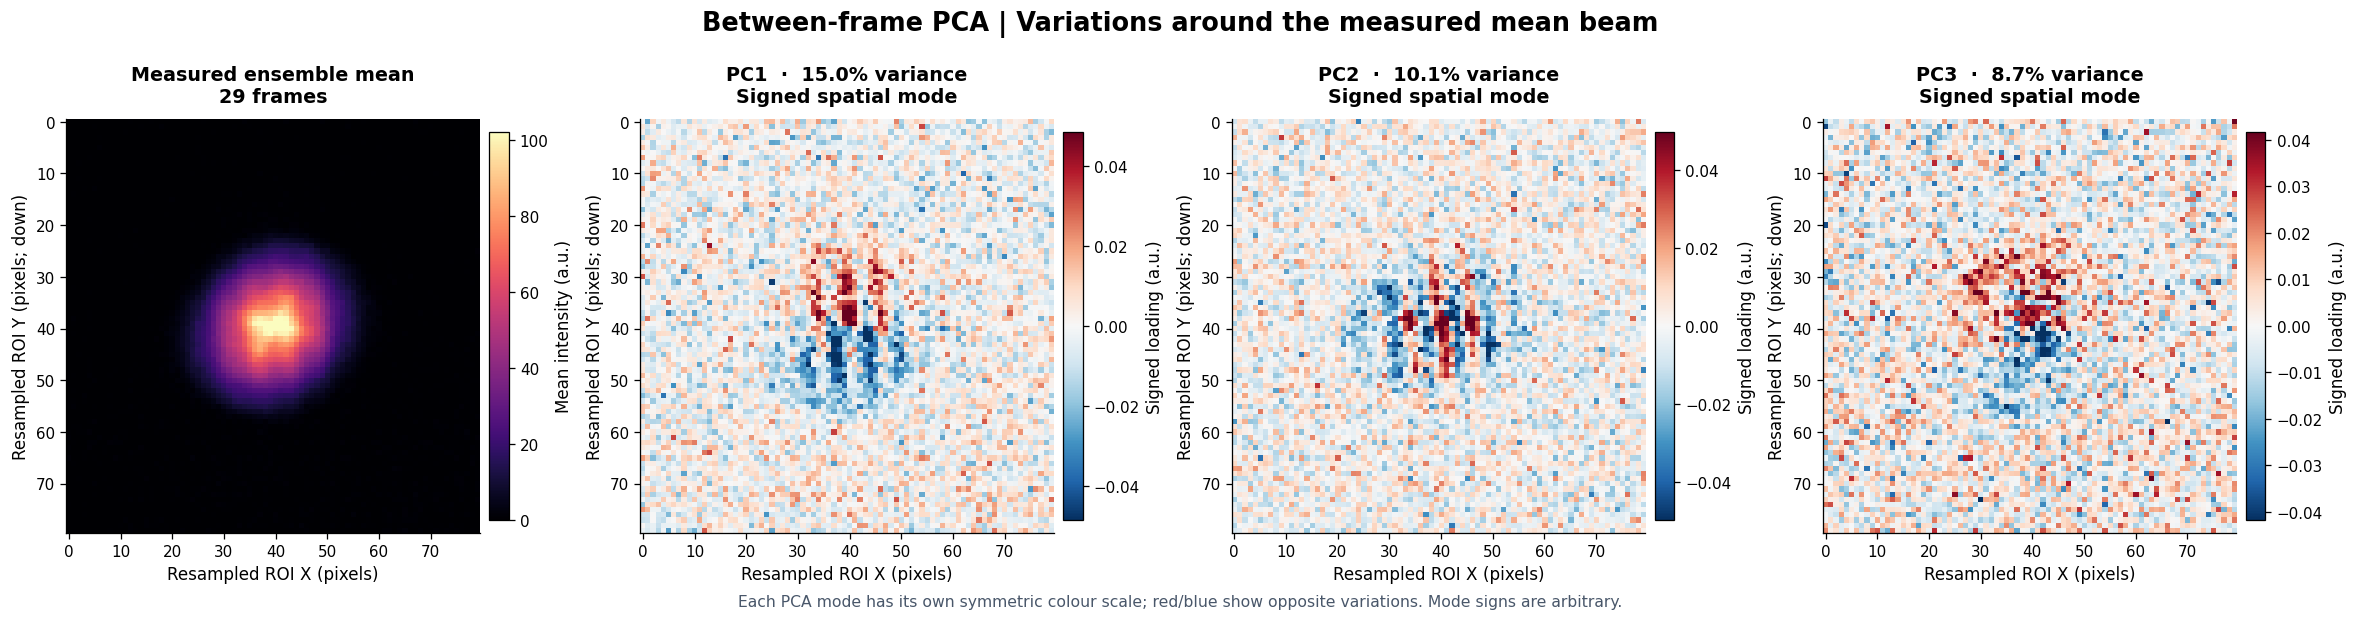

In [ ]:
OUT_DIR = Path(tempfile.mkdtemp(prefix='beam_report_'))

def safe_name(filename):
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', Path(filename).stem)


def plot_beam_summary(item, frames, sd_image, output_dir):
    """One figure for measured beam, model quality, spatial PCA and width variability."""
    meta, roi, fit, iso, pca = (item[key] for key in ('meta', 'roi', 'fit', 'iso', 'pca'))
    sx, sy = meta['sx'], meta['sy']
    x0, y0, x1, y1 = roi
    measured = item['signal'][y0:y1, x0:x1]
    yp, xp = np.mgrid[y0:y1, x0:x1]
    X, Y = xp*sx, yp*sy
    model = gaussian2d(X, Y, *fit['gaussian_params'])
    resid = measured - model
    extent = [(x0-.5)*sx, (x1-.5)*sx, (y1-.5)*sy, (y0-.5)*sy]

    fig = plt.figure(figsize=(17.4, 10.2), layout='constrained', facecolor='white')
    outer = fig.add_gridspec(2, 3, width_ratios=[1.05, 1.05, 1.04], height_ratios=[1, .9])
    ax = np.array([[fig.add_subplot(outer[r, c]) for c in range(3)] for r in range(2)])
    fig.suptitle(f'Laser beam characterization  |  {len(frames)} independent image(s)  |  {meta["plane"]} plane',
                 fontsize=17, weight='bold')

    # One measured map carries both fitted-Gaussian and ISO/PCA shape overlays.
    amp_top = max(float(np.percentile(np.maximum(measured, 0), 99.8)), 1e-6)
    im = ax[0, 0].imshow(np.maximum(measured, 0), origin='upper', extent=extent,
                         cmap='magma', vmin=0, vmax=amp_top, interpolation='nearest')
    ax[0, 0].contour(X, Y, model-fit['fit_offset_counts'],
                     levels=[fit['fit_A_counts']*np.exp(-2)], colors=['#5DE3E4'], linewidths=2.2)
    ax[0, 0].plot([], [], color='#5DE3E4', lw=2.2, label='Gaussian 1/e² contour')
    angle = np.deg2rad(pca['pca_angle_deg_image_y_down'])
    u = np.array([np.cos(angle), np.sin(angle)])
    v = np.array([-np.sin(angle), np.cos(angle)])
    cen = np.array([iso['centroid_x_um'], iso['centroid_y_um']])
    major, minor = pca['pca_major_width_um'], pca['pca_minor_width_um']
    theta = np.linspace(0, 2*np.pi, 260)
    boundary = cen[:, None] + major*u[:, None]*np.cos(theta) + minor*v[:, None]*np.sin(theta)
    ax[0, 0].plot(boundary[0], boundary[1], '--', color='#F3E9AF', lw=1.6,
                  label='ISO/PCA second-moment ellipse')
    ax[0, 0].plot([cen[0]-major*u[0], cen[0]+major*u[0]],
                  [cen[1]-major*u[1], cen[1]+major*u[1]],
                  '-', color='#9EF3A2', lw=2.0, label='PCA major axis')
    ax[0, 0].plot([cen[0]-minor*v[0], cen[0]+minor*v[0]],
                  [cen[1]-minor*v[1], cen[1]+minor*v[1]],
                  '-', color='white', lw=1.7, label='PCA minor axis')
    ax[0, 0].plot(*cen, marker='+', color='white', markersize=10, markeredgewidth=1.8)
    ax[0, 0].set_xlim(extent[:2]); ax[0, 0].set_ylim(extent[2:])
    ax[0, 0].set(title='A  |  Mean beam and shape measurements',
                 xlabel='Camera X (µm)', ylabel='Camera Y (µm; down)')
    ax[0, 0].legend(loc='upper right', fontsize=8, framealpha=.92)
    cb = fig.colorbar(im, ax=ax[0, 0], fraction=.045, pad=.02, shrink=.82)
    cb.set_label('Relative intensity (a.u.)')

    # Residual and variation are intentionally shown only once.
    vmax = max(float(np.percentile(np.abs(resid), 99.5)), .01)
    im2 = ax[0, 1].imshow(resid, origin='upper', extent=extent,
                          cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax[0, 1].set(title=f'B  |  Gaussian residual  ·  core R² = {fit["fit_R2_core"]:.3f}',
                 xlabel='Camera X (µm)', ylabel='Camera Y (µm; down)')
    fig.colorbar(im2, ax=ax[0, 1], fraction=.045, pad=.02, shrink=.82,
                 label='Measured − model (a.u.)')

    if len(frames) > 1:
        local_sd = sd_image[y0:y1, x0:x1]
        im3 = ax[0, 2].imshow(local_sd, origin='upper', extent=extent,
                              cmap='cividis', vmin=0)
        fig.colorbar(im3, ax=ax[0, 2], fraction=.045, pad=.02, shrink=.82,
                     label='Pixelwise sample SD (a.u.)')
        sd_title = 'C  |  Variation between images'
    else:
        ax[0, 2].set_facecolor('#F4F7FA')
        ax[0, 2].set_axis_off()
        ax[0, 2].text(.5, .53, 'Frame-to-frame standard deviation\nrequires at least two independent captures',
                      ha='center', va='center', fontsize=12, color='#516273',
                      transform=ax[0, 2].transAxes)
        sd_title = 'C  |  Image-to-image variation'
    ax[0, 2].set_title(sd_title)
    if len(frames) > 1:
        ax[0, 2].set(xlabel='Camera X (µm)', ylabel='Camera Y (µm; down)')

    # Profiles use a three-pixel average through the fitted centre.
    xc = int(np.clip(round(fit['fit_cx_um']/sx-x0), 1, measured.shape[1]-2))
    yc = int(np.clip(round(fit['fit_cy_um']/sy-y0), 1, measured.shape[0]-2))
    local_sd = sd_image[y0:y1, x0:x1]
    profiles = [
        (ax[1, 0], X[yc, :], measured[yc-1:yc+2, :].mean(axis=0),
         model[yc-1:yc+2, :].mean(axis=0), local_sd[yc-1:yc+2, :].mean(axis=0),
         'D  |  Horizontal profile', 'Camera X (µm)', fit['fit_wx_um']),
        (ax[1, 1], Y[:, xc], measured[:, xc-1:xc+2].mean(axis=1),
         model[:, xc-1:xc+2].mean(axis=1), local_sd[:, xc-1:xc+2].mean(axis=1),
         'E  |  Vertical profile', 'Camera Y (µm)', fit['fit_wy_um'])]
    for axes, pos, obs, pred, sig, title, xlabel, width in profiles:
        axes.plot(pos, obs, color='#196EA5', lw=2, label='Measured average')
        axes.plot(pos, pred, color='#CD683D', lw=1.8, ls='--', label='Gaussian fit')
        if len(frames) > 1:
            axes.fill_between(pos, obs-sig, obs+sig, color='#196EA5', alpha=.17,
                              label='±1 pixelwise SD')
        axes.set(title=f'{title}  ·  Gaussian radius = {width:.1f} µm',
                 xlabel=xlabel, ylabel='Relative intensity (a.u.)')
        axes.grid(alpha=.16)
        axes.legend(loc='upper right', fontsize=8.5)

    # Four independent width statistics; their physical axes are camera X and Y.
    width_fields = [('ISO X', 'ISO width X (um)'), ('ISO Y', 'ISO width Y (um)'),
                    ('Gaussian X', 'Gaussian width X (um)'),
                    ('Gaussian Y', 'Gaussian width Y (um)')]
    mean_width = np.array([np.mean([r['row'][field] for r in frames]) for _,field in width_fields])
    spread = np.array([np.std([r['row'][field] for r in frames],ddof=1)
                       if len(frames)>1 else 0 for _,field in width_fields])
    y_idx = np.arange(4)
    palette = ['#196EA5', '#3A93AD', '#CD683D', '#E39469']
    ax[1, 2].barh(y_idx, mean_width, color=palette, alpha=.88, height=.58)
    if len(frames)>1:
        ax[1, 2].errorbar(mean_width, y_idx, xerr=spread, fmt='none',
                          ecolor='#1B2533', capsize=4, elinewidth=1.5,
                          label='±1 sample SD')
    ax[1, 2].set_yticks(y_idx, [name for name, _ in width_fields])
    ax[1, 2].invert_yaxis()
    ax[1, 2].set(title='F  |  Mean beam radii across images',
                 xlabel='Mean radius (µm)')
    ax[1, 2].grid(axis='x', alpha=.18)
    ax[1, 2].set_axisbelow(True)
    if len(frames)>1:
        ax[1, 2].legend(loc='lower right', fontsize=8.5)

    for axes in ax[0]:
        axes.set_aspect('equal')
    for axes in ax.flat:
        axes.tick_params(direction='out')
    outfile = output_dir / 'Beam_summary.png'
    fig.savefig(outfile, dpi=235, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    return outfile


def plot_between_frame_pca(info, output_dir):
    """Measured ensemble mean and signed PCA mode maps in one horizontal figure."""
    if info is None or not info['modes']:
        return None
    maps = info['modes'][:3]
    n_panels = 1 + len(maps)
    fig, axs = plt.subplots(1, n_panels, figsize=(5.1*n_panels, 5.25),
                            layout='constrained', facecolor='white')
    mean = info['mean_roi']
    h0 = axs[0].imshow(mean, cmap='magma', origin='upper', interpolation='nearest',
                        vmin=0, vmax=max(float(np.quantile(mean, .998)), 1e-9))
    axs[0].set_title(f'Measured ensemble mean\n{len(valid)} frames', fontweight='semibold', pad=11)
    cb = fig.colorbar(h0, ax=axs[0], fraction=.047, pad=.023, shrink=.82)
    cb.set_label('Mean intensity (a.u.)')

    for j, (axes, mode) in enumerate(zip(axs[1:], maps)):
        lim = max(float(np.quantile(np.abs(mode), .995)), 1e-10)
        im = axes.imshow(mode, cmap='RdBu_r', origin='upper',
                         vmin=-lim, vmax=lim, interpolation='nearest')
        axes.set_title(f'PC{j+1}  ·  {100*info["ratios"][j]:.1f}% variance\nSigned spatial mode',
                       fontweight='semibold', pad=11)
        cb = fig.colorbar(im, ax=axes, fraction=.047, pad=.023, shrink=.82)
        cb.set_label('Signed loading (a.u.)')
    for axes in axs:
        axes.set(xlabel='Resampled ROI X (pixels)',
                 ylabel='Resampled ROI Y (pixels; down)')
        axes.set_aspect('equal')
    fig.suptitle('Between-frame PCA | Variations around the measured mean beam',
                 fontsize=16, fontweight='bold')
    fig.text(.5, 0, 'Each PCA mode has its own symmetric colour scale; red/blue show opposite variations. Mode signs are arbitrary.',
             ha='center', va='bottom', fontsize=9.8, color='#49576A')
    outfile = output_dir / 'PCA_mode_maps.png'
    fig.savefig(outfile, dpi=240, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    return outfile


beam_figure = plot_beam_summary(mean_result, valid, sd_signal, OUT_DIR)
pca_figure = plot_between_frame_pca(ensemble_pca, OUT_DIR)

In [ ]:
def save_3d_comparison(item, outdir, show=False, max_samples=100):
    m,roi,fit=item['meta'],item['roi'],item['fit']
    sx,sy=m['sx'],m['sy']
    x0,y0,x1,y1=roi
    original=item['signal'][y0:y1,x0:x1]
    stride=max(1,int(np.ceil(max(original.shape)/max_samples)))
    sl=original[::stride,::stride]
    ypix,xpix=np.mgrid[y0:y1:stride,x0:x1:stride]
    X=xpix*sx; Y=ypix*sy
    measured=np.maximum(sl,0)
    fitted=np.maximum(gaussian2d(X,Y,*fit['gaussian_params']),0)
    ymax=max(measured.max(),fitted.max())
    fig=make_subplots(rows=1,cols=2,specs=[[{'type':'surface'},{'type':'surface'}]],
                      subplot_titles=('Measured averaged intensity','Gaussian model fitted to average'),horizontal_spacing=.03)
    fig.add_trace(go.Surface(x=X,y=Y,z=measured,colorscale='Viridis',
                  cmin=0,cmax=ymax,showscale=True,
                  colorbar=dict(title='Relative counts',x=.46,len=.70)),row=1,col=1)
    fig.add_trace(go.Surface(x=X,y=Y,z=fitted,colorscale='Viridis',
                  cmin=0,cmax=ymax,showscale=False),row=1,col=2)
    for scene in ['scene','scene2']:
        fig.update_layout(**{scene:dict(xaxis_title='x [µm]',yaxis_title='y [µm]',
                                       zaxis_title='relative counts',zaxis=dict(range=[0,ymax*1.1]),
                                       aspectmode='cube', camera=dict(eye=dict(x=1.5,y=1.3,z=.8)))})
    fig.update_layout(title=f"{m['name']} | {m['plane']} | fit R² (core)={fit['fit_R2_core']:.3f}",
                      height=620,width=1270,margin=dict(l=5,r=5,t=100,b=10))
    out=outdir/(safe_name(m['name'])+'_measured_vs_fit_3D.html')
    fig.write_html(str(out),include_plotlyjs=True,full_html=True)
    if show: display(fig)
    return out


three_d_file = save_3d_comparison(mean_result, OUT_DIR, show=False) if MAKE_INTERACTIVE_3D else None
if three_d_file is not None: print('Saved 3D average-image view:',three_d_file.name)

Saved 3D average-image view: AVERAGE_29_independent_frames__measured_vs_fit_3D.html


## 8 · Export

The ZIP contains `beam_results.xlsx` (two tabs: **Widths** and **PCA**), the figure(s), optional averaged-beam 3D HTML, `calibration_and_settings.txt`, and unchanged uploaded files in `source_images/`.

In [ ]:
def style_section(ws, row_no, label, width=7):
    ws.merge_cells(start_row=row_no,start_column=1,end_row=row_no,end_column=width)
    c=ws.cell(row_no,1,label)
    c.fill=PatternFill('solid',fgColor='15324A')
    c.font=Font(name='Calibri',size=11,bold=True,color='FFFFFF')
    c.alignment=Alignment(vertical='center')
    ws.row_dimensions[row_no].height=23

def write_header(ws, labels):
    ws.append(labels)
    for cell in ws[ws.max_row]:
        cell.fill=PatternFill('solid',fgColor='E6EDF4')
        cell.font=Font(name='Calibri',bold=True,color='15324A')
        cell.alignment=Alignment(wrap_text=True,vertical='center')
    ws.row_dimensions[ws.max_row].height=38

def write_data(ws,values):
    ws.append([None if isinstance(v,float) and not np.isfinite(v) else
               v.item() if isinstance(v,(np.integer,np.floating)) else v
               for v in values])
    for c in ws[ws.max_row]:
        c.font=Font(name='Calibri',size=10)
        if isinstance(c.value,(float,int)) and not isinstance(c.value,bool):
            c.number_format='0.000'
    if ws.max_row%2==0:
        for c in ws[ws.max_row]:c.fill=PatternFill('solid',fgColor='F7FAFC')

book=Workbook(); ws=book.active; ws.title='Widths'; ws.sheet_view.showGridLines=False
style_section(ws,1,f'Beam widths | {n} independent image(s) | units: µm')
ws.append(['Each width is a radius (D4σ/2 or Gaussian 1/e²); SD = sample SD between frames.'])
style_section(ws,4,'Batch width summary: mean of frames vs width measured from averaged image')
write_header(ws,['Width (radius)','Mean [µm]','Sample SD [µm]','Mean ± SD [µm]',
                 'Width of average image [µm]','N'])
for metric in ['ISO width X (um)','ISO width Y (um)',
               'Gaussian width X (um)','Gaussian width Y (um)']:
    r=next(t for t in width_stats if t['Parameter']==metric)
    write_data(ws,[metric.replace(' (um)',''),r['Mean of individual images (um)'],
                   r['SD of individual images (um)'],r['Mean ± SD (um)'],
                   r['Width from averaged image (um)'],r['N']])
style_section(ws,11,'Individual image measurements')
write_header(ws,['Image','ISO width X [µm]','ISO width Y [µm]',
                 'Gaussian width X [µm]','Gaussian width Y [µm]',
                 'Gaussian core R²','Quality notes'])
for r in valid:
    v=r['row']
    write_data(ws,[v['Image'],v['ISO width X (um)'],v['ISO width Y (um)'],
                   v['Gaussian width X (um)'],v['Gaussian width Y (um)'],
                   v['Gaussian core R2'],v['Quality notes']])
write_data(ws,[f'AVERAGE IMAGE (N={n})',
               mean_result['row']['ISO width X (um)'],mean_result['row']['ISO width Y (um)'],
               mean_result['row']['Gaussian width X (um)'],mean_result['row']['Gaussian width Y (um)'],
               mean_result['row']['Gaussian core R2'],'Fitted directly to the averaged intensity image'])
ws.freeze_panes='B13'
ws.column_dimensions['A'].width=34
for name in 'BCDEF':ws.column_dimensions[name].width=22
ws.column_dimensions['G'].width=62

pws=book.create_sheet('PCA');pws.sheet_view.showGridLines=False
style_section(pws,1,'Principal component analysis (PCA)')
pws.append(['Spatial PCA uses intensity-weighted covariance, the same moments as ISO D4σ. Angles: measured in camera image coordinates (positive clockwise; image Y downward).'])
style_section(pws,4,'Spatial PCA: major/minor 2σ radii and beam orientation')
write_header(pws,['Image','Major PCA width [µm]','Minor PCA width [µm]',
                  'Angle [deg]','Major variance [%]','Minor / major radius'])
for r in pca_table:
    write_data(pws,[r['Image'],r['PCA major width (um)'],r['PCA minor width (um)'],
                    r['PCA angle (deg)'],r['Major variance (%)'],r['Minor/major width']])
if frame_pca_table:
    row=pws.max_row+2
    style_section(pws,row,f'Between-frame PCA (N={n}): intensity-pattern variation')
    write_header(pws,['Principal component','Explained variance [%]','Number of frames'])
    for r in frame_pca_table:
        write_data(pws,[r['Component'],r['Explained variance (%)'],r['Number of frames']])
    row=pws.max_row+2
    style_section(pws,row,'Frame scores on first two intensity-pattern PCs')
    write_header(pws,['Image','PC1 score','PC2 score'])
    for r in frame_scores_table:
        write_data(pws,[r['Image'],r['PC1 score'],r['PC2 score']])
pws.freeze_panes='B6';pws.column_dimensions['A'].width=35
for name in 'BCDEF':pws.column_dimensions[name].width=26

settings_file = OUT_DIR / 'calibration_and_settings.txt'
measured_scale_x = ref['sx']; measured_scale_y = ref['sy']
lines = [
    'THORIMAGECAM BEAM ANALYSIS — CALIBRATION AND SETTINGS',
    f'Generated (UTC): {datetime.now(timezone.utc).isoformat(timespec="seconds")}',
    '',
    'CAMERA / LENGTH CALIBRATION',
    f'Sensor width × height: {SENSOR_SIZE_PX[0]} × {SENSOR_SIZE_PX[1]} pixels',
    f'Native sensor pixel pitch: X={UM_PER_SENSOR_PIXEL[0]:.6g} µm/pixel; Y={UM_PER_SENSOR_PIXEL[1]:.6g} µm/pixel',
    f'Object-to-sensor magnification: {OBJECT_MAGNIFICATION if OBJECT_MAGNIFICATION is not None else "not supplied"}',
    f'Applied calibration: X={measured_scale_x:.6g} µm/pixel; Y={measured_scale_y:.6g} µm/pixel',
    f'Reported measurement plane: {ref["plane"]}',
    'Image-map convention: X increases rightward; Y increases downward',
    'PCA angle convention: positive clockwise on displayed camera images',
    '',
    'ANALYSIS SETTINGS',
    f'Intensity-normalize before averaging: {NORMALIZE_INTENSITY_FOR_MEAN}',
    f'Centroid-align before averaging: {ALIGN_FOR_MEAN}',
    f'Background polynomial order: {BACKGROUND_ORDER}',
    f'ROI expansion [detection sigma]: {ROI_EXPANSION_SIGMA}',
    f'ROI minimum half-size [pixels]: {ROI_MIN_HALF_SIZE_PX}',
    f'Gaussian fit grid maximum: {GAUSSIAN_FIT_GRID_MAX}',
    f'Full-frame screenshot crops [left,top,right,bottom]: {SCREENSHOT_CROPS}',
    'Beam widths reported as radii (µm): ISO D4σ / 2 and Gaussian 1/e²',
    'Sample standard deviation uses N-1 across independent images',
    'Averaged-image fit is distinct from the mean of individual-image fitted widths',
    '',
    'SOURCE IMAGES (unchanged files stored under source_images/)',
    *[f'  {p.name}' for p in input_paths],
    '',
    'REFERENCE-ONLY IMAGES (archived; deliberately not included in measurement)',
    *([f'  {p.name}' for p in reference_paths] or ['  none']),
    '',
    f'MEASUREMENT IMAGES USED IN AVERAGE ({n})',
    *[f'  {r["meta"]["name"]} — {r["meta"]["kind"]}' for r in valid],
    '',
    'EXCLUDED OR SKIPPED MEASUREMENTS',
    *([f'  {v["Image"]}: {v["Reason"]}' for v in skipped] or ['  none']),
    *([f'  {name}: incompatible calibrated image grid' for name in excluded] or []),
    '',
    'INTERPRETATION',
    '- Original uploads are preserved without modification.',
    '- The width statistics use independent frames; sensor-plane widths require magnification to infer object-plane size.',
]
settings_file.write_text('\n'.join(lines) + '\n',encoding='utf-8')
excel=OUT_DIR/'beam_results.xlsx'
book.save(str(excel))
zip_path=Path.cwd()/ZIP_FILENAME
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as archive:
    for file in sorted(OUT_DIR.iterdir()):
        if file.is_file(): archive.write(file,arcname=file.name)
    for path in input_paths:
        archive.write(path,arcname=f'source_images/{path.name}')
print('\nFINAL ZIP:',zip_path)
print('Workbook: Widths and PCA; archived inputs and calibration included')
with zipfile.ZipFile(zip_path,'r') as check_archive:
    print('Files in ZIP:')
    for filename in check_archive.namelist(): print(' -',filename)
if IN_COLAB and DOWNLOAD_ZIP_IN_COLAB:
    colab_files.download(str(zip_path))



FINAL ZIP: /content/Laser_Beam_Analysis.zip
Workbook: Widths and PCA; archived inputs and calibration included
Files in ZIP:
 - AVERAGE_29_independent_frames__measured_vs_fit_3D.html
 - Beam_summary.png
 - PCA_mode_maps.png
 - beam_results.xlsx
 - calibration_and_settings.txt
 - source_images/Snapshot_YAG-Target_0103.jpg
 - source_images/Snapshot_YAG-Target_0102.jpg
 - source_images/Snapshot_YAG-Target_0101.jpg
 - source_images/Snapshot_YAG-Target_0100.jpg
 - source_images/Snapshot_YAG-Target_0099.jpg
 - source_images/Snapshot_YAG-Target_0098.jpg
 - source_images/Snapshot_YAG-Target_0097.jpg
 - source_images/Snapshot_YAG-Target_0096.jpg
 - source_images/Snapshot_YAG-Target_0095.jpg
 - source_images/Snapshot_YAG-Target_0094.jpg
 - source_images/Snapshot_YAG-Target_0093.jpg
 - source_images/Snapshot_YAG-Target_0092.jpg
 - source_images/Snapshot_YAG-Target_0091.jpg
 - source_images/Snapshot_YAG-Target_0090.jpg
 - source_images/Snapshot_YAG-Target_0089.jpg
 - source_images/Snapshot_YAG-Ta

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reading your results

**Widths** reports radii in µm; the sample SD is variability *between independent images*, not a fit uncertainty. The PCA principal radii come from ISO second moments. Between-frame PCA plots are available only with ≥3 images, and the sign of each eigenimage is arbitrary. Without an imaging-magnification calibration, the physical widths refer to the **camera sensor plane**.